# 🧪 AICE Associate 모의고사 3 · 와인 품질 등급 예측 (다중분류) — 정답 및 해설

> 난이도 ★★★ (실제 시험 수준, 조금 어렵게) · 14문항 · 100점 · 합격 80점 · 제한시간 90분

이 노트북은 **정답 코드 + 해설**입니다. 먼저 문제 노트북을 직접 풀고, 채점한 뒤에 보세요.
맨 아래 채점 셀을 실행하면 100점이 나와야 정상입니다.

---

## 시나리오
와인 유통사 **'AI 소믈리에'** 는 화학 성분 분석 결과만으로 와인의 **품질 등급 `grade`(low / mid / high)** 를 예측하려고 합니다.
레드 와인과 화이트 와인 데이터가 **두 파일로 나뉘어** 있습니다.

이번 회차의 함정: **concat**, **해석 결과를 변수에 저장**, **IQR 이상치**, **순서가 있는 범주 변환**, **다중분류 출력층**

In [1]:
# [준비 셀] 문제가 아닙니다. 그대로 실행하세요.
import os, warnings
os.environ['OMP_NUM_THREADS'] = '1'         # macOS: XGBoost 와 PyTorch 를 한 노트북에서 쓸 때 멈춤 방지 (맨 처음 실행)
warnings.filterwarnings('ignore')            # 불필요한 경고 숨기기
import sys
sys.path.insert(0, '..')                    # 채점기(aice_check.py) 위치
DATA_DIR = '../../data/'

## 데이터 설명 — wine_red.csv, wine_white.csv (컬럼 동일)

| 컬럼 | 설명 | 컬럼 | 설명 |
|---|---|---|---|
| wine_id | 와인 ID | free_sulfur_dioxide | 유리 이산화황 |
| fixed_acidity | 고정 산도 | total_sulfur_dioxide | 총 이산화황 |
| volatile_acidity | 휘발성 산도 | density | 밀도 |
| citric_acid | 구연산 | pH | 산성도 |
| residual_sugar | 잔당 | sulphates | 황산염 |
| chlorides | 염화물 | alcohol | 알코올 도수 |
| **grade** | **품질 등급 low / mid / high ← 예측 대상** | | |

---
### 문항 1 &nbsp;<small>(4점)</small> &nbsp; 라이브러리 불러오기

**pandas → `pd`**, **numpy → `np`**, **matplotlib.pyplot → `plt`**, **seaborn → `sns`** 로 import 하세요.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

> **해설**
>
> 매 시험 공짜 점수입니다. 별칭만 정확히!

---
### 문항 2 &nbsp;<small>(7점)</small> &nbsp; 두 파일 합치기

- `wine_red.csv` → **`df_red`**, `wine_white.csv` → **`df_white`** 로 읽으세요.
- 각각 **`type`** 컬럼을 추가해 값을 **`'red'`**, **`'white'`** 로 넣으세요.
- 두 데이터를 위아래로 이어 붙여(**concat**, **ignore_index=True**) **`df`** 에 저장하세요.

In [3]:
df_red = pd.read_csv(DATA_DIR + 'wine_red.csv')
df_white = pd.read_csv(DATA_DIR + 'wine_white.csv')
df_red['type'] = 'red'
df_white['type'] = 'white'
df = pd.concat([df_red, df_white], ignore_index=True)
print(df.shape)
df['type'].value_counts()

(6497, 14)


type
white    4898
red      1599
Name: count, dtype: int64

> **해설**
>
> - 컬럼이 같은 두 표를 **위아래로** 붙이면 `concat`, **키로 옆에** 붙이면 `merge` 입니다.
> - `ignore_index=True` 가 없으면 인덱스가 0~1598, 0~4897 로 **중복**되어 이후 `loc` 사용 시 엉뚱한 행이 선택될 수 있습니다.
> - `pd.concat(df_red, df_white)` 처럼 **리스트로 감싸지 않으면** 에러입니다.

---
### 문항 3 &nbsp;<small>(6점)</small> &nbsp; 그룹 통계 해석

- `grade` 별 `alcohol` 평균을 **groupby** 로 구해 **`alcohol_by_grade`** 에 저장하세요.
- 평균 alcohol 이 **가장 높은 grade 이름**(문자열)을 **`answer3`** 에 저장하세요.
- **화이트 와인 중 grade 가 `'high'` 인 비율**을 소수 셋째 자리 반올림하여 **`high_ratio_white`** 에 저장하세요.

In [4]:
alcohol_by_grade = df.groupby('grade')['alcohol'].mean()
print(alcohol_by_grade)
answer3 = alcohol_by_grade.idxmax()

white = df[df['type'] == 'white']
high_ratio_white = round((white['grade'] == 'high').mean(), 3)
print(answer3, high_ratio_white)

grade
high    11.555348
low      9.549311
mid     10.520884
Name: alcohol, dtype: float64
high 0.339


> **해설**
>
> - `idxmax()` 는 최댓값의 **인덱스(여기선 grade 이름)** 를 돌려줍니다. `max()` 는 값(숫자)을 돌려주니 헷갈리지 마세요.
> - 해석형 문항은 "답을 변수에 저장" 하거나 "보기 중 고르기" 로 나옵니다. 숫자를 눈으로 읽고 손으로 적으면 반올림 실수가 나기 쉬우니 **코드로 계산해서 저장**하세요.

---
### 문항 4 &nbsp;<small>(6점)</small> &nbsp; 상관관계 분석

- 수치형 컬럼끼리의 상관계수 행렬을 구해 **`corr`** 에 저장하고 **heatmap** 으로 그리세요. (`numeric_only=True`)
- `alcohol` 과의 상관계수 **절댓값**이 가장 큰 컬럼 이름(alcohol 자신 제외)을 **`answer4`** 에 저장하세요.

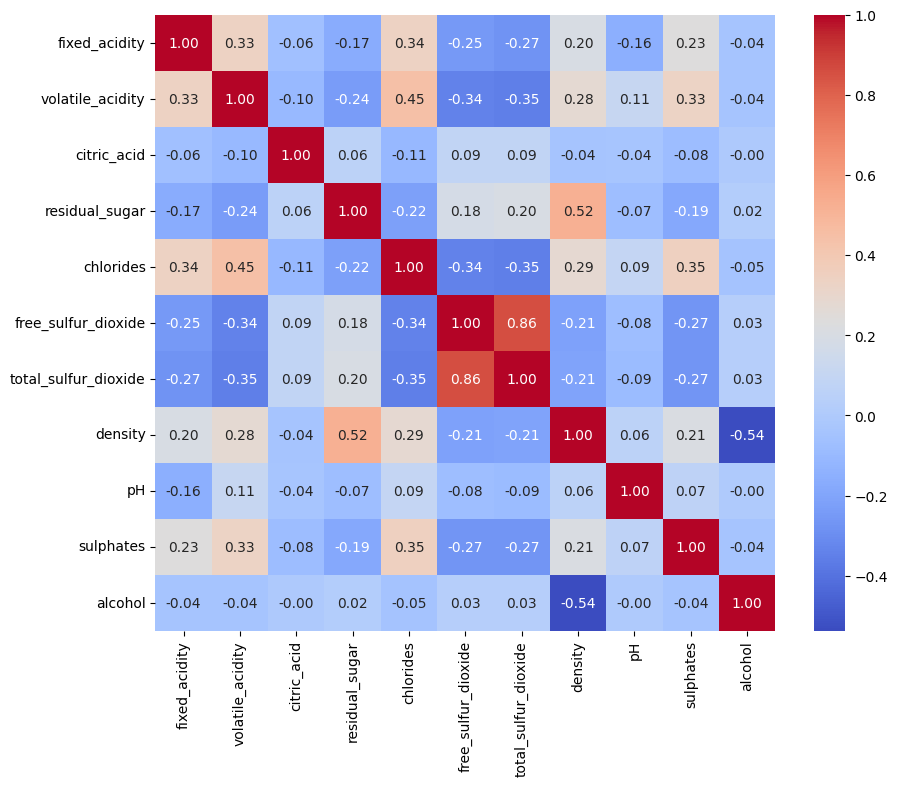

density -0.5368046510742563


In [5]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

answer4 = corr['alcohol'].drop('alcohol').abs().idxmax()
print(answer4, corr.loc['alcohol', answer4])

> **해설**
>
> - 문자열 컬럼(wine_id, grade, type)이 있으면 `df.corr()` 가 에러(또는 경고)를 냅니다 → `numeric_only=True`.
> - **절댓값**: density 는 **음(-)의 상관**이 강합니다(알코올이 많을수록 밀도가 낮음). 절댓값 없이 `idxmax()` 하면 양의 상관만 보게 되어 틀립니다.
> - `.drop('alcohol')` 로 자기 자신(상관계수 1)을 빼는 것도 잊지 마세요.

---
### 문항 5 &nbsp;<small>(7점)</small> &nbsp; 결측치 채우기

`df` 의 수치형 컬럼 결측치를 **각 컬럼의 중앙값**으로 채워 **`df_fill`** 에 저장하세요. (행 삭제 금지)

In [6]:
print(df.isna().sum()[df.isna().sum() > 0])
df_fill = df.fillna(df.median(numeric_only=True))
print(df_fill.isna().sum().sum())

residual_sugar    128
pH                 96
sulphates          63
dtype: int64
0


> **해설**
>
> - `df.median(numeric_only=True)` 는 컬럼별 중앙값 Series. `fillna` 에 Series 를 넣으면 **컬럼 이름에 맞춰** 각각 채워 줍니다.
> - 컬럼별로 하나씩 써도 정답: `df_fill['pH'] = df_fill['pH'].fillna(df_fill['pH'].median())` … (이 경우 `df_fill = df.copy()` 부터)

---
### 문항 6 &nbsp;<small>(8점)</small> &nbsp; IQR 이상치 제거

`df_fill` 의 **`total_sulfur_dioxide`** 에 대해 IQR 방식으로 이상치를 제거하세요.
- Q1 = 25% 분위수, Q3 = 75% 분위수, IQR = Q3 − Q1
- **Q1 − 1.5×IQR 이상, Q3 + 1.5×IQR 이하** 인 행만 남겨 **`df_iqr`** 에 저장

In [7]:
q1 = df_fill['total_sulfur_dioxide'].quantile(0.25)
q3 = df_fill['total_sulfur_dioxide'].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
df_iqr = df_fill[(df_fill['total_sulfur_dioxide'] >= lower) & (df_fill['total_sulfur_dioxide'] <= upper)]
print(lower, upper, df_fill.shape, '->', df_iqr.shape)

-104.0 328.0 (6497, 14) -> (6460, 14)


> **해설**
>
> - 조건 두 개는 `&` 로 묶고 **각 조건을 괄호로** 감싸야 합니다. `and` 를 쓰면 `ValueError: The truth value of a Series is ambiguous` 에러.
> - "이상/이하" → `>=`, `<=`. 다른 정답: `df_fill[df_fill['total_sulfur_dioxide'].between(lower, upper)]` (between 은 기본적으로 양 끝 포함)
> - boxplot 의 수염(whisker) 바깥 점들이 바로 이 기준의 이상치입니다.

---
### 문항 7 &nbsp;<small>(7점)</small> &nbsp; 타깃 변환 + 컬럼 삭제

`df_iqr` 에서 **`wine_id`** 컬럼을 삭제하고, `grade` 를 **low → 0, mid → 1, high → 2** 로 바꿔 **`df_clean`** 에 저장하세요.

In [8]:
df_clean = df_iqr.drop('wine_id', axis=1)
df_clean['grade'] = df_clean['grade'].map({'low': 0, 'mid': 1, 'high': 2})
df_clean['grade'].value_counts()

grade
1    2452
0    2096
2    1912
Name: count, dtype: int64

> **해설**
>
> - **함정**: LabelEncoder 를 쓰면 알파벳 순서라 `high=0, low=1, mid=2` 가 됩니다. 문제에서 지정한 번호와 다르니 0점!
>   순서를 직접 정해야 할 때는 `map(딕셔너리)` 또는 `replace(딕셔너리)` 를 쓰세요.
> - `drop` 이 새 DataFrame 을 돌려주므로 그 다음 대입은 안전합니다.

---
### 문항 8 &nbsp;<small>(7점)</small> &nbsp; 원-핫 인코딩

`df_clean` 의 **`type`** 컬럼만 **get_dummies(drop_first=True)** 로 인코딩하여 **`df_preset`** 에 저장하세요.

In [9]:
df_preset = pd.get_dummies(df_clean, columns=['type'], drop_first=True)
df_preset.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,grade,type_white
0,7.4,0.770,0.29,1.7,0.107,1.0,6.0,0.99560,2.99,0.54,11.0,0,False
1,6.1,0.483,0.29,3.1,0.023,17.0,38.0,0.99643,3.34,0.66,10.6,0,False
2,10.6,0.748,0.00,2.7,0.111,11.0,23.0,0.99721,3.33,0.71,10.3,0,False
3,6.2,0.629,0.03,3.1,0.048,29.0,89.0,0.99989,3.31,0.36,8.0,0,False
4,8.6,0.503,0.46,2.2,0.072,4.0,6.0,0.99706,3.14,0.72,10.9,1,False


> **해설**
>
> - 값이 red/white 두 개라 `drop_first=True` 면 `type_white` 컬럼 하나만 남습니다 (1이면 화이트, 0이면 레드).
> - `columns=['type']` 처럼 **리스트**로 주세요.

---
### 문항 9 &nbsp;<small>(8점)</small> &nbsp; 학습/평가 데이터 분리

`grade` 를 y, 나머지를 X 로 하여 **test_size=0.25, stratify=y, random_state=2025** 로 나누고 **`X_train, X_test, y_train, y_test`** 에 저장하세요.

In [10]:
from sklearn.model_selection import train_test_split

X = df_preset.drop('grade', axis=1)
y = df_preset['grade']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=2025)
print(X_train.shape, X_test.shape)

(4845, 12) (1615, 12)


> **해설**
>
> random_state 가 42 가 아닐 때도 있습니다. 숫자를 문제에서 그대로 옮기세요.

---
### 문항 10 &nbsp;<small>(7점)</small> &nbsp; 정규화

**MinMaxScaler** 를 **`scaler`** 로 만들어 **X_train 기준으로 fit** 하고, 결과를 **`X_train_s`**, **`X_test_s`** 에 저장하세요.

In [11]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train_s.min(), X_train_s.max())

0.0 1.0000000000000002


> **해설**
>
> - MinMaxScaler: 0~1 범위로. StandardScaler: 평균 0, 표준편차 1. 문제에서 지정한 것을 쓰세요.
> - X_test_s 는 0~1 을 살짝 벗어날 수 있습니다 (train 기준으로 맞췄기 때문 — 정상).

---
### 문항 11 &nbsp;<small>(8점)</small> &nbsp; 머신러닝 모델 2개 학습

`X_train_s, y_train` 으로 두 모델을 학습하세요.
- **LogisticRegression(max_iter=1000, random_state=42)** → **`lr`**
- **XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42)** → **`xgb`**

In [12]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)

xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42)
xgb.fit(X_train_s, y_train)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


> **해설**
>
> - XGBoost 는 sklearn 이 아니라 **`xgboost` 패키지**에서 import 합니다 (시험 허용 문서 7개 중 하나).
> - XGBClassifier 는 타깃이 **0부터 시작하는 정수**여야 합니다. 7번에서 grade 를 0/1/2 로 바꾼 이유 중 하나입니다.
> - LogisticRegression 은 `max_iter` 가 작으면 `ConvergenceWarning` 이 납니다.

---
### 문항 12 &nbsp;<small>(8점)</small> &nbsp; 모델 비교

`X_test_s` 에 대한 정확도를 **`lr_acc`**, **`xgb_acc`** 에 저장하고,
정확도가 더 높은 모델의 이름을 **`'lr'` 또는 `'xgb'`** 문자열로 **`best_model_name`** 에 저장하세요.

In [13]:
from sklearn.metrics import accuracy_score, classification_report

lr_acc = accuracy_score(y_test, lr.predict(X_test_s))
xgb_acc = accuracy_score(y_test, xgb.predict(X_test_s))
best_model_name = 'xgb' if xgb_acc > lr_acc else 'lr'
print(f'LR {lr_acc:.4f} | XGB {xgb_acc:.4f} -> {best_model_name}')
print(classification_report(y_test, xgb.predict(X_test_s), target_names=['low', 'mid', 'high']))

LR 0.6966 | XGB 0.6687 -> lr
              precision    recall  f1-score   support

         low       0.75      0.71      0.73       524
         mid       0.57      0.60      0.59       613
        high       0.72      0.71      0.71       478

    accuracy                           0.67      1615
   macro avg       0.68      0.67      0.68      1615
weighted avg       0.67      0.67      0.67      1615



> **해설**
>
> - 조건부 대입 `A if 조건 else B` 를 쓰면 한 줄로 끝납니다.
> - 다중분류 `classification_report` 에서 클래스별 precision/recall 을 보면 **mid 등급을 가장 헷갈려** 합니다 (가운데 등급이라 양쪽과 겹침).

---
### 문항 13 &nbsp;<small>(10점)</small> &nbsp; 딥러닝 모델 학습 + 조기 종료 (PyTorch)

- **`torch.manual_seed(42)`** 후 텐서 변환: X_train_s, X_test_s → **`X_train_t`**, **`X_test_t`** (float32) / y_train, y_test → **`y_train_t`**, **`y_test_t`** (**torch.long**, 1차원 **(N,)**)
- **`train_loader`**: **batch_size=64, shuffle=True**
- **`model`** = nn.Sequential: **Linear(입력 수, 64)** → **ReLU** → **Dropout(0.2)** → **Linear(64, 32)** → **ReLU** → **Linear(32, 3)** (Softmax 를 **넣지 마세요**)
- **`loss_fn`** = **nn.CrossEntropyLoss()**, **`optimizer`** = **Adam(lr=0.001)**
- **최대 100 epoch** 학습, 매 epoch 마다 **`history`** 의 **`'loss'`**, **`'val_loss'`**(eval 모드, X_test_t 전체) 기록
- **조기 종료 (patience=10)**: val_loss 가 지금까지의 최솟값보다 **작아지면** 그 가중치를 **`best_state`** = `copy.deepcopy(model.state_dict())` 로 보관하고 **`torch.save(best_state, 'best_model.pt')`** 로 저장하세요. **10 epoch 연속** 작아지지 않으면 학습을 멈추세요.
- 학습이 끝나면 **`model.load_state_dict(best_state)`** 로 최고 성능 가중치를 복원하세요.

In [14]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)     # 정수 라벨 0/1/2
y_test_t = torch.tensor(y_test.values, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)

model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 64), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 3),                       # 클래스 3개의 점수(logit)
)
loss_fn = nn.CrossEntropyLoss()             # softmax + NLL 을 한 번에
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history = {'loss': [], 'val_loss': []}
best_loss, best_state, wait, patience = float('inf'), None, 0, 10
for epoch in range(100):
    model.train()
    batch_losses = []
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_test_t), y_test_t).item()
    history['loss'].append(sum(batch_losses) / len(batch_losses))
    history['val_loss'].append(val_loss)

    if val_loss < best_loss:                # 최고 기록 갱신 → 저장, 대기 횟수 초기화
        best_loss, wait = val_loss, 0
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, 'best_model.pt')
    else:                                   # 갱신 실패 → 대기 +1, patience 도달 시 중단
        wait += 1
        if wait >= patience:
            break

model.load_state_dict(best_state)           # 최고 성능 가중치로 되돌리기
print(f"학습 epoch 수: {len(history['loss'])} | 최저 val_loss {best_loss:.4f}")

학습 epoch 수: 27 | 최저 val_loss 0.6492


> **해설**
>
> - **다중분류 = 출력 `Linear(…, 클래스 수)` + `nn.CrossEntropyLoss()`**. CrossEntropyLoss 가 내부에서 softmax 를 하므로 출력층에 `nn.Softmax` 를 넣지 않습니다 (넣으면 softmax 두 번 → 학습이 느려지고 성능 하락).
> - **라벨 dtype**: CrossEntropyLoss 는 y 를 **`torch.long` 1차원 (N,)** 으로 받습니다. 원-핫 (N, 3) 이나 float 로 주면 의미가 달라지거나 에러가 납니다 (`expected scalar type Long`). 이진분류의 BCEWithLogitsLoss(float, (N,1))와 반대이니 짝으로 외우세요.
> - **`copy.deepcopy`** 가 핵심: `best_state = model.state_dict()` 만 쓰면 **같은 텐서를 가리키는 참조**라서 이후 학습으로 값이 계속 바뀝니다 → 복원해도 마지막 가중치가 됩니다.
> - 조기 종료는 "검증 성적이 더 이상 좋아지지 않으면 멈추고, 가장 좋았던 순간으로 되돌리기" 입니다. `torch.save` 는 체크포인트 파일 저장 (`model.load_state_dict(torch.load('best_model.pt'))` 로 다시 불러올 수 있음).
> - 비교는 `<` (엄격히 작아질 때만 갱신). 같은 값이면 갱신으로 보지 않습니다.

---
### 문항 14 &nbsp;<small>(7점)</small> &nbsp; 딥러닝 예측 + 평가

- eval 모드 + `torch.no_grad()` 에서 `model(X_test_t)` 의 출력에 **argmax(dim=1)** 를 적용해 클래스 번호 **1차원 numpy 배열** **`y_pred`** 를 만드세요.
- 정확도를 **`dnn_acc`** 에 저장하고, **loss / val_loss** 학습 곡선을 그리세요 (title **'Loss'**, xlabel **'Epochs'**, ylabel **'Loss'**, legend **['loss', 'val_loss']**).

[[0.853 0.145 0.002]
 [0.341 0.599 0.06 ]
 [0.454 0.514 0.032]]
DNN accuracy: 0.6954


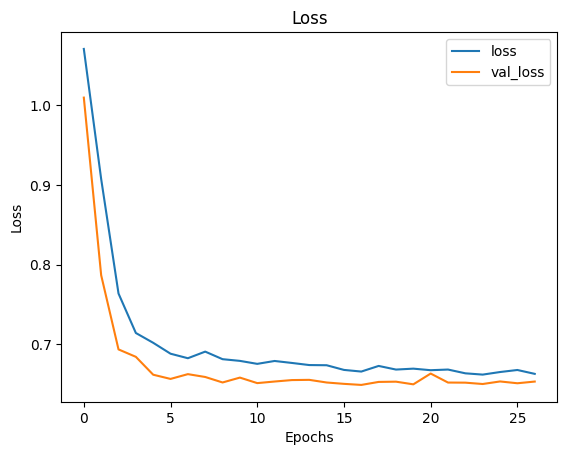

In [15]:
model.eval()
with torch.no_grad():
    logits = model(X_test_t)
print(torch.softmax(logits[:3], dim=1).numpy().round(3))   # 참고: 확률로 보면
y_pred = logits.argmax(dim=1).numpy()
dnn_acc = accuracy_score(y_test, y_pred)
print(f'DNN accuracy: {dnn_acc:.4f}')

plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('Loss'); plt.xlabel('Epochs'); plt.ylabel('Loss')
plt.legend(['loss', 'val_loss'])
plt.show()

> **해설**
>
> - 출력은 행마다 3개의 점수(logit). 가장 큰 점수의 **위치** 가 예측 클래스 → `argmax(dim=1)`. softmax 를 씌워도 순서는 같아서 결과가 동일합니다.
> - `dim=1` 을 빼먹으면 전체 텐서에서 최댓값 위치 **숫자 하나**만 나옵니다.
> - 이진분류(BCEWithLogits)는 `sigmoid > 0.5`, 다중분류(CrossEntropy)는 `argmax`. 짝으로 기억하세요.
> - 학습 곡선에서 val_loss 가 바닥을 찍고 다시 오르기 시작한 지점이 과적합 시작점, 그로부터 10 epoch 뒤가 조기 종료 지점입니다.

---
## 🏁 채점
아래 셀을 실행하면 문항별 결과와 총점이 나옵니다. 틀린 문항은 → 뒤의 이유를 읽고 고쳐 본 뒤 다시 채점해 보세요.

In [16]:
import aice_check
aice_check.grade_exam3(globals())

📋 모의고사 3 · 와인 등급 예측 (다중분류) 채점 결과
────────────────────────────────────────────────────────────────
✅  1번 [ 4/ 4점] pd, np, plt, sns import
✅  2번 [ 7/ 7점] type 컬럼 추가 후 concat(ignore_index=True) → df
✅  3번 [ 6/ 6점] grade 별 alcohol 평균 → alcohol_by_grade, 최고 grade → answer3, white 의 high 비율 → high_ratio_white
✅  4번 [ 6/ 6점] 수치형 상관행렬 → corr, alcohol 과 |상관계수| 최대 컬럼 → answer4
✅  5번 [ 7/ 7점] 결측치를 각 컬럼 중앙값으로 채우기 → df_fill
✅  6번 [ 8/ 8점] total_sulfur_dioxide IQR 이상치 제거 → df_iqr
✅  7번 [ 7/ 7점] grade 를 low→0, mid→1, high→2 로 변환, wine_id 삭제 → df_clean
✅  8번 [ 7/ 7점] type 원-핫 인코딩(drop_first=True) → df_preset
✅  9번 [ 8/ 8점] train_test_split(test_size=0.25, stratify=y, random_state=2025)
✅ 10번 [ 7/ 7점] MinMaxScaler: train 으로 fit → X_train_s, X_test_s
✅ 11번 [ 8/ 8점] LogisticRegression → lr, XGBClassifier → xgb 학습
✅ 12번 [ 8/ 8점] 정확도 lr_acc, xgb_acc / 더 높은 모델 이름 → best_model_name
✅ 13번 [10/10점] PyTorch 다중분류 DNN + 조기 종료(patience=10) + best_state 복원 → model, history
✅ 14번 [ 7/ 7점] argmax(dim=1) 로 클래스 예측 → y_

100